### Task 1:

In [17]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Load Dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
columns = [
    "age", "workclass", "fnlwgt", "education", "education-num", "marital-status",
    "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss",
    "hours-per-week", "native-country", "income"
]

df = pd.read_csv(url, names=columns, sep=',\s*', engine='python')

df = df.replace('?', np.nan).dropna()

<>:17: SyntaxWarning: invalid escape sequence '\s'
<>:17: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_491/3767282364.py:17: SyntaxWarning: invalid escape sequence '\s'
  df = pd.read_csv(url, names=columns, sep=',\s*', engine='python')


In [18]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 30162 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             30162 non-null  int64 
 1   workclass       30162 non-null  object
 2   fnlwgt          30162 non-null  int64 
 3   education       30162 non-null  object
 4   education-num   30162 non-null  int64 
 5   marital-status  30162 non-null  object
 6   occupation      30162 non-null  object
 7   relationship    30162 non-null  object
 8   race            30162 non-null  object
 9   sex             30162 non-null  object
 10  capital-gain    30162 non-null  int64 
 11  capital-loss    30162 non-null  int64 
 12  hours-per-week  30162 non-null  int64 
 13  native-country  30162 non-null  object
 14  income          30162 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [22]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,30162.000000,3.016200e+04,30162.000000,30162.000000,30162.000000,30162.000000
mean,38.437902,1.897938e+05,10.121312,1092.007858,88.372489,40.931238
std,13.134665,1.056530e+05,2.549995,7406.346497,404.298370,11.979984
min,17.000000,1.376900e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.176272e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.784250e+05,10.000000,0.000000,0.000000,40.000000
75%,47.000000,2.376285e+05,13.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [23]:
df.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0


In [24]:
y = (df['income'].str.contains('>50K')).astype(int)

sex_attribute = df['sex']
X = df.drop(columns=['income', 'sex'])

numeric_features = ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
categorical_features = ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'native-country']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_features)
    ])

X_train, X_test, y_train, y_test, sex_train, sex_test = train_test_split(
    X, y, sex_attribute, test_size=0.30, random_state=42, stratify=y
)

model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

model_pipeline.fit(X_train, y_train)
baseline_preds = model_pipeline.predict(X_test)
print("Task 1 Complete:")

Task 1 Complete:


### Task 2

In [25]:
!pip install -q fairlearn

from fairlearn.metrics import MetricFrame, selection_rate, true_positive_rate, false_positive_rate
from sklearn.metrics import accuracy_score

# accuracy
overall_accuracy = accuracy_score(y_test, baseline_preds)
print(f"Baseline model : Logistic Regression   Accuracy : {overall_accuracy:.2f}\n")

metrics = {
    'accuracy': accuracy_score,
    'selection_rate': selection_rate,
    'tpr': true_positive_rate,
    'fpr': false_positive_rate
}

metric_frame = MetricFrame(
    metrics=metrics,
    y_true=y_test,
    y_pred=baseline_preds,
    sensitive_features=sex_test
)

print("GROUP     ACCURACY   SELECTION_RATE    TPR     FPR")
for group in metric_frame.by_group.index:
    row = metric_frame.by_group.loc[group]
    print(f"{group:<10} {row['accuracy']:.2f}         {row['selection_rate']:.2f}          {row['tpr']:.2f}    {row['fpr']:.2f}")

Baseline model : Logistic Regression   Accuracy : 0.85

GROUP     ACCURACY   SELECTION_RATE    TPR     FPR
Female     0.92         0.09          0.53    0.03
Male       0.81         0.26          0.61    0.10


### Task 3

In [26]:
from fairlearn.metrics import demographic_parity_difference, demographic_parity_ratio, equalized_odds_difference

dp_diff = demographic_parity_difference(y_test, baseline_preds, sensitive_features=sex_test)
dp_ratio = demographic_parity_ratio(y_test, baseline_preds, sensitive_features=sex_test)
eo_diff = equalized_odds_difference(y_test, baseline_preds, sensitive_features=sex_test)

print(f"Demographic parity difference : {dp_diff:.2f}")
flag = "(< 0.80 -> BIAS)" if dp_ratio < 0.80 else "(PASS)"
print(f"Demographic parity ratio (DI)  : {dp_ratio:.2f}   {flag}")
print(f"Equalized odds difference      : {eo_diff:.2f}")

Demographic parity difference : 0.17
Demographic parity ratio (DI)  : 0.34   (< 0.80 -> BIAS)
Equalized odds difference      : 0.09


### Task 4

In [27]:
from fairlearn.postprocessing import ThresholdOptimizer

to_dp = ThresholdOptimizer(
    estimator=model_pipeline,
    constraints="demographic_parity",
    predict_method='predict_proba'
)

to_dp.fit(X_train, y_train, sensitive_features=sex_train)

to_dp_preds = to_dp.predict(X_test, sensitive_features=sex_test)

to_dp_acc = accuracy_score(y_test, to_dp_preds)
to_dp_mf = MetricFrame(
    metrics=metrics,
    y_true=y_test,
    y_pred=to_dp_preds,
    sensitive_features=sex_test
)

t_dp_diff = demographic_parity_difference(y_test, to_dp_preds, sensitive_features=sex_test)
t_eo_diff = equalized_odds_difference(y_test, to_dp_preds, sensitive_features=sex_test)

print("ThresholdOptimizer demographic_parity metrics evaluated.")

ThresholdOptimizer demographic_parity metrics evaluated.


### Task 5

In [28]:
to_eo = ThresholdOptimizer(
    estimator=model_pipeline,
    constraints="equalized_odds",
    predict_method='predict_proba'
)

to_eo.fit(X_train, y_train, sensitive_features=sex_train)

to_eo_preds = to_eo.predict(X_test, sensitive_features=sex_test)

to_eo_acc = accuracy_score(y_test, to_eo_preds)
to_eo_mf = MetricFrame(
    metrics=metrics,
    y_true=y_test,
    y_pred=to_eo_preds,
    sensitive_features=sex_test
)

t_eo_dp_diff = demographic_parity_difference(y_test, to_eo_preds, sensitive_features=sex_test)
t_eo_eo_diff = equalized_odds_difference(y_test, to_eo_preds, sensitive_features=sex_test)

print("ThresholdOptimizer equalized_odds metrics evaluated.")

ThresholdOptimizer equalized_odds metrics evaluated.


### Task 6

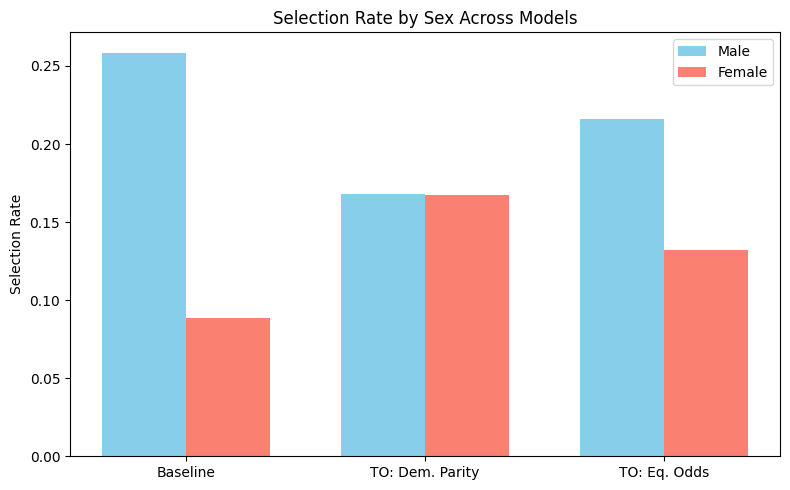

MODEL                 ACC    SEL_M   SEL_F   DP_DIFF   EO_DIFF
Baseline              0.85   0.26    0.09    0.17      0.09
TO: demographic_par.  0.83   0.17    0.17    0.00      0.31
TO: equalized_odds    0.83   0.22    0.13    0.08      0.02
No single model satisfies both fairness definitions.


In [30]:
import matplotlib.pyplot as plt

baseline_sel = metric_frame.by_group['selection_rate']
dp_sel = to_dp_mf.by_group['selection_rate']
eo_sel = to_eo_mf.by_group['selection_rate']

labels = ['Baseline', 'TO: Dem. Parity', 'TO: Eq. Odds']
male_rates = [baseline_sel['Male'], dp_sel['Male'], eo_sel['Male']]
female_rates = [baseline_sel['Female'], dp_sel['Female'], eo_sel['Female']]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(x - width/2, male_rates, width, label='Male', color='skyblue')
rects2 = ax.bar(x + width/2, female_rates, width, label='Female', color='salmon')

ax.set_ylabel('Selection Rate')
ax.set_title('Selection Rate by Sex Across Models')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
plt.tight_layout()

plt.savefig('selection_rate_by_sex.png')
plt.show()

print("MODEL                 ACC    SEL_M   SEL_F   DP_DIFF   EO_DIFF")
print(f"Baseline              {overall_accuracy:.2f}   {baseline_sel['Male']:.2f}    {baseline_sel['Female']:.2f}    {dp_diff:.2f}      {eo_diff:.2f}")
print(f"TO: demographic_par.  {to_dp_acc:.2f}   {dp_sel['Male']:.2f}    {dp_sel['Female']:.2f}    {t_dp_diff:.2f}      {t_eo_diff:.2f}")
print(f"TO: equalized_odds    {to_eo_acc:.2f}   {eo_sel['Male']:.2f}    {eo_sel['Female']:.2f}    {t_eo_dp_diff:.2f}      {t_eo_eo_diff:.2f}")
print("No single model satisfies both fairness definitions.")